# 04 — Loss landscapes of trajectory matching on a chaotic flow

For a chaotic system, the trajectory-matching (single-shooting) objective

$$\mathcal L_T(\theta)=\frac{1}{T}\int_0^T \big\|x(t;\theta,x_0)-y(t)\big\|^2_{\Sigma^{-1}}\,dt$$

has parameter sensitivities $\partial x(t)/\partial\theta$ that grow like $e^{\lambda_{\max} t}$. As $T$ grows, $\mathcal L_T$ becomes rough: it has many local minima, and its gradients are exponentially large and badly conditioned. Multiple shooting splits $[0,T]$ into windows of length $\tau\ll\lambda_{\max}^{-1}$ that restart from estimated states, which bounds the sensitivity by $e^{\lambda_{\max}\tau}$.

This notebook contains:

1. exact 2-D slices $\mathcal L(\sigma,\rho)$ for Lorenz-63;
2. growth of the gradient norm with the horizon;
3. a basin-of-attraction study for parameter estimation;
4. random restarts of the full sparse-library problem, with and without continuation;
5. filter-normalised slices of the black-box network's loss.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from src import experiment as E, plotting as P
from src.systems import simulate
from src.integrators import rk4_step
from src.sweeps import basin_job, run_parallel
P.setup()
MET = "../results/metrics"
torch.set_num_threads(2)
s = E.get_sys("lorenz"); ref = E.reference("lorenz")
std = ref["std"]; h = 0.01
SIG, RHO, BETA = 10.0, 28.0, 8.0 / 3.0

## 1. Exact slices of the loss surface

In [2]:
def lorenz_batch(x, sig, rho, beta):
    X, Y, Z = x[..., 0], x[..., 1], x[..., 2]
    return np.stack([sig * (Y - X), X * (rho - Z) - Y, X * Y - beta * Z], axis=-1)

x0 = ref["X_ref"][0]
T_max = 8.0
t_obs, Y_obs = simulate(s, x0, T_max, h)            # noise-free observations on the RK4 grid

def single_shooting(sig, rho, T):
    n = int(round(T / h))
    x = np.broadcast_to(x0, sig.shape + (3,)).copy()
    acc = np.zeros(sig.shape)
    f = lambda z: lorenz_batch(z, sig, rho, BETA)
    with np.errstate(all="ignore"):
        for k in range(1, n + 1):
            x = rk4_step(f, x, h)
            acc += np.sum(((x - Y_obs[k]) / std) ** 2, axis=-1)
    return acc / n

def multiple_shooting(sig, rho, T, tau=0.2):
    n, m = int(round(T / h)), int(round(tau / h))
    acc = np.zeros(sig.shape); cnt = 0
    f = lambda z: lorenz_batch(z, sig, rho, BETA)
    for j0 in range(0, n, m):
        x = np.broadcast_to(Y_obs[j0], sig.shape + (3,)).copy()   # node at the observation
        for k in range(j0 + 1, min(j0 + m, n) + 1):
            x = rk4_step(f, x, h)
            acc += np.sum(((x - Y_obs[k]) / std) ** 2, axis=-1); cnt += 1
    return acc / cnt

sg, rg = np.meshgrid(np.linspace(4, 16, 161), np.linspace(18, 38, 161))
t0 = time.time()
surfaces = {f"ss{T}": single_shooting(sg, rg, T) for T in (0.5, 2.0, 8.0)}
surfaces["ms8"] = multiple_shooting(sg, rg, 8.0)
print(f"{time.time() - t0:.1f} s")
np.savez_compressed(f"{MET}/landscape_sigma_rho.npz", sigma=sg, rho=rg, **surfaces)

7.6 s


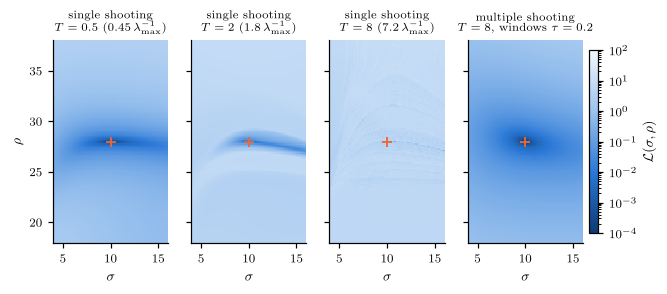

In [3]:
titles = {"ss0.5": "single shooting\n" + r"$T=0.5$ ($0.45\,\lambda_{\max}^{-1}$)",
          "ss2.0": "single shooting\n" + r"$T=2$ ($1.8\,\lambda_{\max}^{-1}$)",
          "ss8.0": "single shooting\n" + r"$T=8$ ($7.2\,\lambda_{\max}^{-1}$)",
          "ms8": "multiple shooting\n" + r"$T=8$, windows $\tau=0.2$"}
fig, axes = plt.subplots(1, 4, figsize=(7.4, 2.4), sharey=True)
for ax, (k, L) in zip(axes, surfaces.items()):
    Lc = np.clip(np.nan_to_num(L, nan=1e6, posinf=1e6), 1e-4, 1e2)
    im = ax.pcolormesh(sg, rg, Lc, norm=LogNorm(1e-4, 1e2), cmap=P.SEQ.reversed(), shading="auto", rasterized=True)
    ax.plot(SIG, RHO, "+", color="#eb6834", ms=7, mew=1.2)
    ax.set_title(titles[k], fontsize=7.5); ax.set_xlabel(r"$\sigma$"); ax.grid(False)
axes[0].set_ylabel(r"$\rho$")
cb = fig.colorbar(im, ax=axes, pad=0.01, shrink=0.9); cb.set_label(r"$\mathcal L(\sigma,\rho)$")
P.save(fig, "fig04_landscape_sigma_rho")
plt.show()

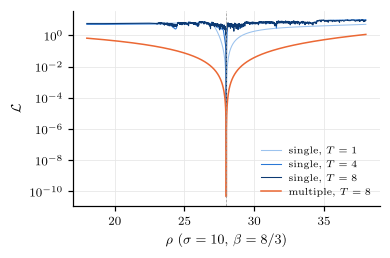

In [4]:
# one-dimensional slice through the truth at full resolution
rho_line = np.linspace(18, 38, 4001)
sig_line = np.full_like(rho_line, SIG)
fig, ax = plt.subplots(figsize=(3.6, 2.3))
for T, c in [(1.0, "#9cc3ee"), (4.0, "#2a78d6"), (8.0, "#0d3a73")]:
    ax.semilogy(rho_line, single_shooting(sig_line, rho_line, T), color=c, lw=0.7, label=rf"single, $T={T:g}$")
ax.semilogy(rho_line, multiple_shooting(sig_line, rho_line, 8.0), color="#eb6834", lw=1.0, label=r"multiple, $T=8$")
ax.axvline(RHO, color="#999999", lw=0.5, ls="--")
ax.set_xlabel(r"$\rho$ ($\sigma=10$, $\beta=8/3$)"); ax.set_ylabel(r"$\mathcal L$")
ax.legend(frameon=False, fontsize=6.5, loc="lower right")
P.save(fig, "fig04_landscape_slice")
plt.show()

## 2. Gradient magnitude against the horizon

The tangent dynamics $\dot\xi = J(x)\,\xi + \partial_\theta f$ give $\|\partial_\theta x(t)\|\sim e^{\lambda_{\max} t}$, so $\|\nabla_\theta\mathcal L_T\|$ should grow at a rate close to $\lambda_{\max}$ (the time average in $\mathcal L_T$ is dominated by its end point). We measure it by automatic differentiation at 64 random parameter vectors within $\pm 5\%$ of the truth.

fitted growth rate of the median gradient norm: 0.684  (lambda_max = 0.9056)


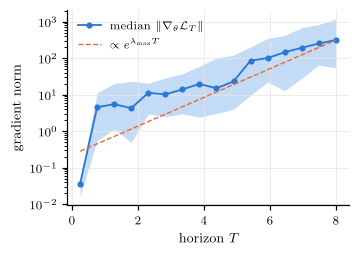

In [5]:
torch.set_default_dtype(torch.float64)
gen = torch.Generator().manual_seed(0)
th = torch.tensor([SIG, RHO, BETA]) * (1 + 0.05 * (2 * torch.rand(64, 3, generator=gen) - 1))
Yt = torch.as_tensor(Y_obs); st = torch.as_tensor(std); x0t = torch.as_tensor(x0)

def grad_norms(T):
    p = th.clone().requires_grad_(True)
    f = lambda z: torch.stack([p[:, 0] * (z[:, 1] - z[:, 0]), z[:, 0] * (p[:, 1] - z[:, 2]) - z[:, 1],
                               z[:, 0] * z[:, 1] - p[:, 2] * z[:, 2]], dim=1)
    x = x0t.expand(64, 3).clone(); acc = 0.0; n = int(round(T / h))
    for k in range(1, n + 1):
        x = rk4_step(f, x, h)
        acc = acc + (((x - Yt[k]) / st) ** 2).sum(1)
    (acc / n).sum().backward()
    return p.grad.norm(dim=1).numpy()

Ts = np.linspace(0.25, 8.0, 16)
G = np.array([grad_norms(T) for T in Ts])
med = np.median(G, axis=1)
slope = np.polyfit(Ts[Ts > 2], np.log(med[Ts > 2]), 1)[0]
print(f"fitted growth rate of the median gradient norm: {slope:.3f}  (lambda_max = {s.lyap})")
fig, ax = plt.subplots(figsize=(3.3, 2.3))
ax.fill_between(Ts, np.percentile(G, 10, 1), np.percentile(G, 90, 1), color="#9cc3ee", alpha=0.6, lw=0)
ax.semilogy(Ts, med, "o-", ms=3, color="#2a78d6", label=r"median $\|\nabla_\theta\mathcal L_T\|$")
ax.semilogy(Ts, med[-1] * np.exp(s.lyap * (Ts - Ts[-1])), "--", color="#eb6834", lw=0.9, label=r"$\propto e^{\lambda_{\max}T}$")
ax.set_xlabel(r"horizon $T$"); ax.set_ylabel("gradient norm"); ax.legend(frameon=False)
P.save(fig, "fig04_gradient_growth")
plt.show()
pd.DataFrame(dict(T=Ts, median=med, p10=np.percentile(G, 10, 1), p90=np.percentile(G, 90, 1))).to_csv(f"{MET}/gradient_growth.csv", index=False)

## 3. Basins of attraction for parameter estimation

There are 96 random initial guesses, uniform in $[0.5,1.5]\times(\sigma,\rho,\beta)$, and data on $[0,4]$ sampled every $0.05$ with 1% noise. All starts are optimised in parallel with Adam on $\log\theta$ for 1500 iterations. A start counts as a success when its final relative parameter error is below 1%.

In [6]:
rng = np.random.default_rng(3)
T_b, dt_b = 4.0, 0.05
tb, Xb = simulate(s, x0, T_b, dt_b)
Yb = Xb + 0.01 * std * rng.standard_normal(Xb.shape)
Ybt = torch.as_tensor(Yb)
theta_true = torch.tensor([SIG, RHO, BETA])
init = theta_true * torch.as_tensor(0.5 + rng.random((96, 3)))
sub = int(round(dt_b / h))

def field(p):
    return lambda z: torch.stack([p[:, 0:1] * (z[..., 1] - z[..., 0]),
                                  z[..., 0] * (p[:, 1:2] - z[..., 2]) - z[..., 1],
                                  z[..., 0] * z[..., 1] - p[:, 2:3] * z[..., 2]], dim=-1)

def loss_single(p, T):
    n = int(round(T / dt_b)); f = field(p)
    x = Ybt[0].expand(p.shape[0], 1, 3).clone(); acc = 0
    for k in range(1, n + 1):
        for _ in range(sub): x = rk4_step(f, x, h)
        acc = acc + (((x[:, 0] - Ybt[k]) / st) ** 2).sum(-1)
    return acc / n

def loss_multiple(p, K):
    # nodes at the observations, windows of K intervals, all windows in parallel
    f = field(p); n = len(Ybt) - 1; starts = torch.arange(0, n - K + 1)
    x = Ybt[starts].expand(p.shape[0], len(starts), 3).clone(); acc = 0
    for k in range(1, K + 1):
        for _ in range(sub): x = rk4_step(f, x, h)
        acc = acc + (((x - Ybt[starts + k]) / st) ** 2).sum(-1).mean(-1)
    return acc / K

def optimise(loss_fn, iters=1500, lr=0.02, schedule=None):
    logp = torch.log(init.clone()).requires_grad_(True)
    opt = torch.optim.Adam([logp], lr=lr)
    for it in range(iters):
        arg = schedule(it) if schedule else None
        L = loss_fn(torch.exp(logp), arg) if schedule else loss_fn(torch.exp(logp))
        L = torch.where(torch.isfinite(L), L, torch.zeros_like(L))   # frozen if diverged
        opt.zero_grad(); L.sum().backward()
        with torch.no_grad():
            logp.grad.nan_to_num_(0.0).clamp_(-1e3, 1e3)
        opt.step()
    p = torch.exp(logp).detach()
    return ((p - theta_true).norm(dim=1) / theta_true.norm()).numpy()

t0 = time.time()
results = {
    "single, T=1": optimise(lambda p: loss_single(p, 1.0)),
    "single, T=4": optimise(lambda p: loss_single(p, 4.0)),
    "multiple, K=4 (0.2)": optimise(lambda p: loss_multiple(p, 4)),
    "multiple, K=20 (1.0)": optimise(lambda p: loss_multiple(p, 20)),
    "multiple, K: 1->20": optimise(lambda p, K: loss_multiple(p, K),
                                   schedule=lambda it: [1, 2, 4, 8, 12, 20][min(5, it // 250)]),
}
print(f"{(time.time() - t0) / 60:.1f} min")
basin = pd.DataFrame({k: v for k, v in results.items()})
basin.to_csv(f"{MET}/basin_parametric.csv", index=False)
succ = (basin < 1e-2).mean().rename("success rate")
succ.to_frame().T

32.9 min


,"single, T=1","single, T=4","multiple, K=4 (0.2)","multiple, K=20 (1.0)","multiple, K: 1->20"
success rate,0.416667,0.0,1.0,0.0,0.0


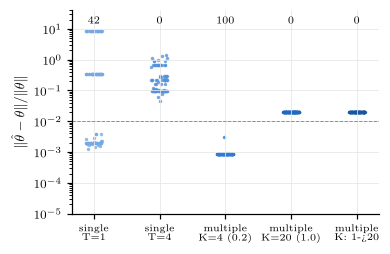

In [7]:
fig, ax = plt.subplots(figsize=(3.6, 2.4))
order = list(results)
for i, k in enumerate(order):
    v = np.clip(np.nan_to_num(results[k], nan=10.0), 1e-5, 10)
    ax.scatter(np.full(len(v), i) + 0.25 * (np.random.default_rng(i).random(len(v)) - 0.5), v, s=5,
               color=P.SEQ(0.45 + 0.5 * i / len(order)), alpha=0.8, lw=0)
    ax.text(i, 15, f"{np.mean(v < 1e-2):.0%}", ha="center", fontsize=7)
ax.axhline(1e-2, color="#eb6834", lw=0.6, ls="--")
ax.set_yscale("log"); ax.set_ylim(1e-5, 40)
ax.set_xticks(range(len(order))); ax.set_xticklabels([k.replace(", ", "\n") for k in order], fontsize=6.5)
ax.set_ylabel(r"$\|\hat\theta-\theta\|/\|\theta\|$")
P.save(fig, "fig04_basins_parametric")
plt.show()

## 4. Random restarts of the sparse-library problem

Here all $p\times d=30$ coefficients are unknown. Random initialisations $\tilde\Xi_0 = c\,\mathcal N(0,\overline{\tilde\Xi_{\rm OLS}^2})$ are drawn at three scales $c\in\{0.03,0.1,0.3\}$, 8 per scale (no information about the true coefficients is used). Each is trained either with the full continuation (Levenberg–Marquardt flow-map stage, then $K=1,2,3,5,\dots$) or directly at the final window length $K_{\max}$. We report the dense coefficient error before any thresholding; a run counts as a success below 0.2 (the dense fit also absorbs noise, so even a run in the right basin keeps an error of about 0.1 before thresholding).

In [8]:
cases = [("lorenz", 4/15, 0.01), ("lorenz", 1/15, 0.01)]
scales = [0.03, 0.1, 0.3]
jobs = [(n, r, e, k, cont, c) for (n, r, e) in cases for c in scales for k in range(8) for cont in (True, False)]
t0 = time.time()
bas = pd.DataFrame(run_parallel(basin_job, jobs, workers=2, log_every=24))
print(f"{(time.time() - t0) / 60:.1f} min")
bas.to_csv(f"{MET}/basin_library.csv", index=False)
bas["success"] = bas.coef_err_dense < 0.2
bas.groupby(["dt_ratio", "init_scale", "strategy"]).agg(success=("success", "mean"),
    median_err=("coef_err_dense", "median"), median_K=("K_final", "median")).round(4)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


24/96 jobs done


48/96 jobs done


72/96 jobs done


96/96 jobs done


15.5 min


success  median_err  median_K
dt_ratio init_scale strategy                                   
0.066667 0.03       continuation    1.000      0.1372      15.0
                    direct          0.000      1.0126       1.0
         0.10       continuation    1.000      0.1371      15.0
                    direct          0.000      1.1375       1.0
         0.30       continuation    1.000      0.1370      15.0
                    direct          0.000      1.7479       1.0
0.266667 0.03       continuation    1.000      0.0956       4.0
                    direct          0.000      1.0614       1.0
         0.10       continuation    0.750      0.0956       4.0
                    direct          0.000      1.3668       1.0
         0.30       continuation    0.125      2.4401       1.0
                    direct          0.000      2.9769       1.0

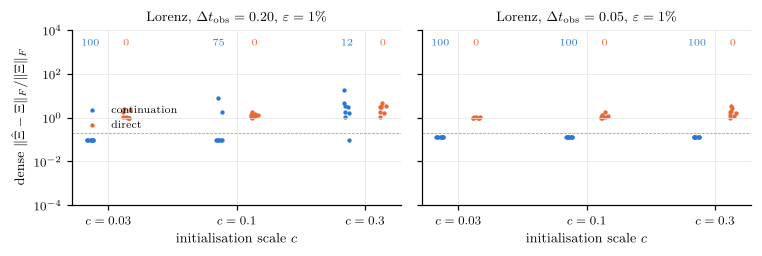

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.4), sharey=True)
for ax, (n, r, e) in zip(axes, cases):
    for k, (strat, col) in enumerate([("continuation", "#2a78d6"), ("direct", "#eb6834")]):
        for j, c in enumerate(scales):
            v = bas[(bas.dt_ratio == r) & (bas.strategy == strat) & (bas.init_scale == c)].coef_err_dense.fillna(1e3).clip(1e-4, 1e3)
            x = j + (k - 0.5) * 0.28 + 0.06 * (np.random.default_rng(j + 10 * k).random(len(v)) - 0.5)
            ax.scatter(x, v, s=8, color=col, lw=0, label=strat if j == 0 else None)
            ax.text(j + (k - 0.5) * 0.28, 2e3, f"{np.mean(v < 0.2):.0%}", ha="center", fontsize=6.5, color=col)
    ax.set_yscale("log"); ax.set_ylim(1e-4, 1e4); ax.axhline(0.2, color="#999999", lw=0.5, ls="--")
    ax.set_xticks(range(len(scales))); ax.set_xticklabels([rf"$c={c:g}$" for c in scales])
    ax.set_title(rf"Lorenz, $\Delta t_{{\rm obs}}={r*0.75:.2f}$, $\varepsilon={int(e*100)}\%$")
    ax.set_xlabel(r"initialisation scale $c$")
axes[0].set_ylabel(r"dense $\|\hat\Xi-\Xi\|_F/\|\Xi\|_F$"); axes[0].legend(frameon=False, fontsize=7, loc="center left")
fig.tight_layout()
P.save(fig, "fig04_basins_library")
plt.show()

## 5. Loss landscape of the black-box network

We use the filter-normalised random directions of Li et al. (2018): $\theta(\alpha,\beta)=\theta^\star+\alpha\,\delta_1+\beta\,\delta_2$, where each filter (row of a weight matrix) of $\delta_i$ is rescaled to the norm of the matching filter of $\theta^\star$. The trained N1 model (Lorenz, $\Delta t_{\rm obs}=0.05$, $\varepsilon=1\%$) is evaluated on windows of $K=1$, of the training length $K=15$, and of $K=60$ ($4\,t_{\rm char}$, close to single shooting).

146 s


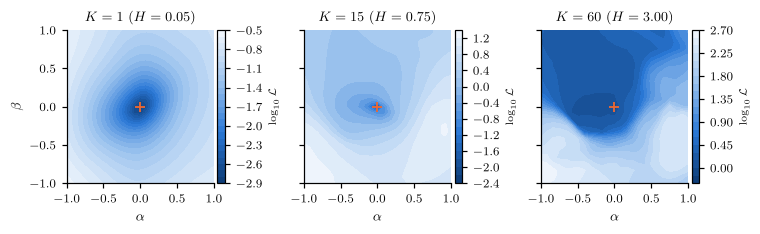

In [10]:
from src.node import MLPField, window_loss, valid_starts
ck = torch.load(f"../results/models/{E._tag('lorenz', 'N1-MLP', 1/15, 0.01, 0)}.pt", weights_only=False)
ds = E.make_dataset("lorenz", 1/15, 0.01, 0)
Yfit = np.concatenate([Y for _, Y in ds["fit"]])
model = E.build_neural("N1-MLP", ds, None, None)
model.load_state_dict(ck["state"])
tr = ck["train"]; scale = Yfit.std(0)
theta_star = [p.detach().clone() for p in model.parameters()]
g = torch.Generator().manual_seed(7)

def filter_normalised():
    d = []
    for p in theta_star:
        r = torch.randn(p.shape, generator=g)
        if p.dim() == 2:
            r = r * (p.norm(dim=1, keepdim=True) / (r.norm(dim=1, keepdim=True) + 1e-12))
        else:
            r = torch.zeros_like(p)        # biases are left at their trained values
        d.append(r)
    return d

d1, d2 = filter_normalised(), filter_normalised()
alphas = np.linspace(-1, 1, 25)
nn_surf = {}
t0 = time.time()
for K in (1, 15, 60):
    st_ = valid_starts(tr["seg"], K)
    st_ = st_[torch.randperm(len(st_), generator=g)[:192]]
    Z = np.zeros((len(alphas), len(alphas)))
    with torch.no_grad():
        for i, a in enumerate(alphas):
            for j, b in enumerate(alphas):
                for p, p0, u, v in zip(model.parameters(), theta_star, d1, d2):
                    p.copy_(p0 + a * u + b * v)
                Z[j, i] = window_loss(model, tr, scale, K, st_).item()
        for p, p0 in zip(model.parameters(), theta_star):
            p.copy_(p0)
    nn_surf[K] = Z
print(f"{time.time() - t0:.0f} s")
np.savez_compressed(f"{MET}/landscape_nn.npz", alphas=alphas, **{f"K{k}": v for k, v in nn_surf.items()})
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.2), sharey=True)
A, B = np.meshgrid(alphas, alphas)
for ax, (K, Z) in zip(axes, nn_surf.items()):
    Zc = np.clip(np.nan_to_num(Z, nan=1e4, posinf=1e4), 1e-4, 1e4)
    im = ax.contourf(A, B, np.log10(Zc), levels=24, cmap=P.SEQ.reversed())
    ax.plot(0, 0, "+", color="#eb6834", ms=7, mew=1.2)
    ax.set_title(rf"$K={K}$ ($H={K * 0.05:.2f}$)"); ax.set_xlabel(r"$\alpha$"); ax.grid(False)
    fig.colorbar(im, ax=ax, pad=0.02).set_label(r"$\log_{10}\mathcal L$", fontsize=7)
axes[0].set_ylabel(r"$\beta$")
fig.tight_layout()
P.save(fig, "fig04_nn_landscape")
plt.show()